# Sleep Staging — 03: Feature Engineering

**Objetivo:** transformar los epochs generados por la NB2 final en un dataset tabular de features clásicas para construir un baseline de machine learning interpretable.

La notebook conserva la trazabilidad temporal y de QC de cada epoch (`source_epoch_index`, `recording_onset_s`, `qc_status`, `review_mask`) y reutiliza resultados previos solo cuando siguen siendo compatibles con los archivos actuales de NB2.


---
## 0. Setup

El backend gráfico se configura antes de importar `pyplot` para evitar problemas con el kernel de VS Code.


In [1]:
from pathlib import Path
import gc
import math
import warnings

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from scipy.integrate import trapezoid
from scipy.signal import welch
from scipy.stats import skew, kurtosis

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

# La NB2 final guarda sus salidas aquí.
SUBJECT_DATA_DIR = Path("../data/processed")
OUTPUT_DIR = SUBJECT_DATA_DIR
CHUNKS_DIR = OUTPUT_DIR / "feature_chunks"
FIGURES_DIR = Path("../reports/figures")

FINAL_PARQUET = OUTPUT_DIR / "features_full.parquet"
FINAL_NPZ = OUTPUT_DIR / "features_full.npz"
CATALOG_PATH = OUTPUT_DIR / "feature_catalog.csv"

for directory in (OUTPUT_DIR, CHUNKS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

EXPECTED_SFREQ = 100
EPOCH_DURATION = 30
CHUNK_SIZE = 5000
EPS = 1e-12
RANDOM_STATE = 42
HIGH_CORR_THRESHOLD = 0.95
MAX_SAMPLES_PER_STAGE = 3000

SIGNAL_BAND = (0.5, 35.0)

FREQ_BANDS = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "sigma": (12.0, 15.0),
    "beta": (15.0, 30.0),
}

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_COLORS = {
    "W": "#e74c3c",
    "N1": "#f39c12",
    "N2": "#3498db",
    "N3": "#2c3e50",
    "REM": "#27ae60",
}

METADATA_COLS = [
    "epoch_global",
    "epoch_in_subject",
    "source_epoch_index",
    "recording_onset_s",
    "label",
    "subject",
    "qc_status",
    "qc_reason",
    "review_mask",
]

print("Setup completado.")
print("Entrada:", SUBJECT_DATA_DIR.resolve())
print("Salida:", OUTPUT_DIR.resolve())


Setup completado.
Entrada: C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed
Salida: C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed


---
## 1. Carga eficiente

Primero se comprueba si el dataset tabular final ya existe. Si existe, se evita cargar `X`, que puede ocupar varios GB.


In [2]:
def decode_text(value):
    """Convierte bytes y escalares NumPy a texto."""
    return value.decode("utf-8") if isinstance(value, bytes) else str(value)


def infer_channels_from_features(columns):
    """Recupera nombres de canales desde columnas canal__feature."""
    return sorted({col.split("__", 1)[0] for col in columns if "__" in col})


In [3]:
subject_files = sorted(SUBJECT_DATA_DIR.glob("SN*.npz"))

if not subject_files:
    raise FileNotFoundError(
        f"No se encontraron archivos SN*.npz en:\n{SUBJECT_DATA_DIR.resolve()}"
    )

# Resumen liviano de los outputs actuales de NB2.
current_n_epochs = 0
for path in subject_files:
    with np.load(path, allow_pickle=True) as data:
        current_n_epochs += len(data["y"])

current_subject_ids = [path.stem for path in subject_files]
newest_input_mtime = max(path.stat().st_mtime for path in subject_files)

cache_valid = False
features_df = None

if FINAL_PARQUET.exists():
    try:
        cached_df = pd.read_parquet(FINAL_PARQUET)

        has_metadata = all(col in cached_df.columns for col in METADATA_COLS)
        same_epochs = len(cached_df) == current_n_epochs
        same_subjects = (
            set(cached_df["subject"].astype(str).unique())
            == set(current_subject_ids)
            if "subject" in cached_df.columns
            else False
        )
        up_to_date = FINAL_PARQUET.stat().st_mtime >= newest_input_mtime

        # La versión actual elimina la duplicación exacta var/hjorth_activity.
        has_old_var_features = any(
            col.endswith("__var") for col in cached_df.columns
        )

        cache_valid = (
            has_metadata
            and same_epochs
            and same_subjects
            and up_to_date
            and not has_old_var_features
        )

        if cache_valid:
            features_df = cached_df
            print("Dataset de features vigente. Se reutiliza el Parquet existente.")
        else:
            print("Dataset de features desactualizado. Se recalculará.")

    except Exception as exc:
        print(f"No se pudo validar el dataset previo ({exc}). Se recalculará.")

if not cache_valid:
    # Si cambia NB2, no se mezclan chunks viejos con nuevos.
    for path in CHUNKS_DIR.glob("features_*.parquet"):
        path.unlink()

    for path in (FINAL_PARQUET, FINAL_NPZ, CATALOG_PATH):
        if path.exists():
            path.unlink()

    NEED_EXTRACTION = True
else:
    NEED_EXTRACTION = False
    FEATURE_COLS = [
        col for col in features_df.columns if col not in METADATA_COLS
    ]
    y = features_df["label"].to_numpy(dtype=np.int8)
    subjects = features_df["subject"].astype(str).to_numpy()
    CH_NAMES = infer_channels_from_features(FEATURE_COLS)
    SFREQ = EXPECTED_SFREQ
    X = None

    print(f"Shape cargado: {features_df.shape}")
    print(f"Features: {len(FEATURE_COLS)}")

print(f"Outputs NB2: {len(subject_files)} sujetos, {current_n_epochs} epochs")


Outputs NB2: 149 sujetos, 135471 epochs


### 1.1 Carga de señales solo cuando es necesaria


In [4]:
if NEED_EXTRACTION:
    required_keys = {
        "X",
        "y",
        "recording_onset_s",
        "source_epoch_index",
        "qc_status",
        "qc_reason",
        "review_mask",
        "channel_names",
        "processed_sfreq",
        "signal_unit",
    }

    X_parts = []
    y_parts = []
    subject_parts = []
    source_epoch_parts = []
    onset_parts = []
    qc_status_parts = []
    qc_reason_parts = []
    review_mask_parts = []

    reference_shape = None
    reference_channels = None
    reference_sfreq = None

    for path in subject_files:
        subject_id = path.stem

        with np.load(path, allow_pickle=True) as data:
            missing = required_keys.difference(data.files)
            if missing:
                raise KeyError(
                    f"{subject_id}: faltan variables de NB2: {sorted(missing)}"
                )

            X_subject = data["X"]
            y_subject = data["y"].astype(np.int8)
            source_epoch_subject = data["source_epoch_index"].astype(np.int64)
            onset_subject = data["recording_onset_s"].astype(np.float64)
            qc_status_subject = data["qc_status"].astype(str)
            qc_reason_subject = data["qc_reason"].astype(str)
            review_subject = data["review_mask"].astype(bool)

            channels_subject = [
                decode_text(ch) for ch in data["channel_names"]
            ]
            sfreq_subject = float(
                np.asarray(data["processed_sfreq"]).squeeze()
            )
            unit_subject = decode_text(
                np.asarray(data["signal_unit"]).squeeze()
            )

        lengths = [
            len(X_subject),
            len(y_subject),
            len(source_epoch_subject),
            len(onset_subject),
            len(qc_status_subject),
            len(qc_reason_subject),
            len(review_subject),
        ]

        if len(set(lengths)) != 1:
            raise ValueError(f"{subject_id}: metadata y señales no están alineadas")

        if X_subject.ndim != 3:
            raise ValueError(f"{subject_id}: shape inválido {X_subject.shape}")

        if reference_shape is None:
            reference_shape = X_subject.shape[1:]
            reference_channels = channels_subject
            reference_sfreq = sfreq_subject
        else:
            if X_subject.shape[1:] != reference_shape:
                raise ValueError(
                    f"{subject_id}: se esperaba {reference_shape}, "
                    f"pero se encontró {X_subject.shape[1:]}"
                )
            if channels_subject != reference_channels:
                raise ValueError(f"{subject_id}: canales inconsistentes con NB2")
            if not np.isclose(sfreq_subject, reference_sfreq):
                raise ValueError(f"{subject_id}: frecuencia inconsistente con NB2")

        if unit_subject not in {"uV", "µV"}:
            raise ValueError(
                f"{subject_id}: unidad inesperada '{unit_subject}', se esperaba uV"
            )

        X_parts.append(X_subject)
        y_parts.append(y_subject)
        subject_parts.append(np.full(len(y_subject), subject_id, dtype=object))
        source_epoch_parts.append(source_epoch_subject)
        onset_parts.append(onset_subject)
        qc_status_parts.append(qc_status_subject)
        qc_reason_parts.append(qc_reason_subject)
        review_mask_parts.append(review_subject)

    X = np.concatenate(X_parts)
    y = np.concatenate(y_parts)
    subjects = np.concatenate(subject_parts).astype(str)
    source_epoch_indices = np.concatenate(source_epoch_parts)
    recording_onsets = np.concatenate(onset_parts)
    qc_statuses = np.concatenate(qc_status_parts).astype(str)
    qc_reasons = np.concatenate(qc_reason_parts).astype(str)
    review_masks = np.concatenate(review_mask_parts).astype(bool)

    del (
        X_parts,
        y_parts,
        subject_parts,
        source_epoch_parts,
        onset_parts,
        qc_status_parts,
        qc_reason_parts,
        review_mask_parts,
    )
    gc.collect()

    n_epochs, n_channels, n_samples = X.shape
    CH_NAMES = reference_channels
    SFREQ = reference_sfreq

    assert n_epochs == current_n_epochs
    assert len(y) == len(subjects) == n_epochs
    assert np.isclose(SFREQ, EXPECTED_SFREQ)
    assert len(CH_NAMES) == n_channels
    assert np.isfinite(X).all()
    assert set(np.unique(y)).issubset(STAGE_MAP)

    print(f"Archivos:      {len(subject_files)}")
    print(f"X:             {X.shape}")
    print(f"Memoria de X:  {X.nbytes / 1024**3:.2f} GB")
    print(f"SFREQ:         {SFREQ:g} Hz")
    print(f"Canales:       {CH_NAMES}")
    print(f"Sujetos:       {len(np.unique(subjects))}")


Archivos:      149
X:             (135471, 7, 3000)
Memoria de X:  10.60 GB
SFREQ:         100 Hz
Canales:       ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2', 'EOG E1-M2', 'EOG E2-M2', 'EMG chin']
Sujetos:       149


---
## 2. Canales y estrategia de features


In [5]:
def infer_channel_type(channel_name):
    """Clasifica un canal por su nombre."""
    name = channel_name.upper()

    if "EEG" in name:
        return "EEG"
    if "EOG" in name:
        return "EOG"
    if "EMG" in name:
        return "EMG"
    return "OTHER"


channel_catalog = pd.DataFrame({
    "channel": CH_NAMES,
    "channel_type": [infer_channel_type(ch) for ch in CH_NAMES],
})

display(channel_catalog)


,channel,channel_type
0,EEG F4-M1,EEG
1,EEG C4-M1,EEG
2,EEG O2-M1,EEG
3,EEG C3-M2,EEG
4,EOG E1-M2,EOG
5,EOG E2-M2,EOG
6,EMG chin,EMG


---
## 3. Funciones de extracción


In [6]:
def safe_float(value, default=0.0):
    """Convierte a float y reemplaza valores no finitos."""
    value = float(value)
    return value if np.isfinite(value) else float(default)


def temporal_features(sig):
    """Features de dominio temporal para un canal de un epoch."""
    zero_crossings = np.mean(np.signbit(sig[:-1]) != np.signbit(sig[1:]))
    return {
        "mean": safe_float(np.mean(sig)),
        "std": safe_float(np.std(sig)),
        "rms": safe_float(np.sqrt(np.mean(sig ** 2))),
        "ptp": safe_float(np.ptp(sig)),
        "skew": safe_float(skew(sig, bias=False)),
        "kurt": safe_float(kurtosis(sig, fisher=True, bias=False)),
        "zcr": safe_float(zero_crossings),
    }


def hjorth_features(sig):
    """Parámetros de Hjorth: activity, mobility y complexity."""
    d1 = np.diff(sig)
    d2 = np.diff(d1)

    activity = np.var(sig)
    mobility = np.sqrt((np.var(d1) + EPS) / (activity + EPS))
    complexity = (
        np.sqrt((np.var(d2) + EPS) / (np.var(d1) + EPS))
        / (mobility + EPS)
    )

    return {
        "hjorth_activity": safe_float(activity),
        "hjorth_mobility": safe_float(mobility),
        "hjorth_complexity": safe_float(complexity),
    }


def permutation_entropy(sig):
    """Entropía de permutación de Bandt-Pompe para order=3, delay=1."""
    n = len(sig) - 2
    if n <= 0:
        return 0.0

    patterns = np.stack(
        (sig[:n], sig[1:n + 1], sig[2:n + 2]),
        axis=1,
    )

    ordinal = np.argsort(patterns, axis=1, kind="mergesort")

    # Codifica cada una de las 6 permutaciones posibles.
    codes = ordinal[:, 0] * 9 + ordinal[:, 1] * 3 + ordinal[:, 2]
    counts = np.bincount(codes, minlength=27)
    counts = counts[counts > 0]

    probabilities = counts / counts.sum()

    entropy_value = -np.sum(
        probabilities * np.log2(probabilities + EPS)
    )
    entropy_value /= np.log2(6)

    return safe_float(entropy_value)

def complexity_features(sig):
    return {
        "perm_entropy": permutation_entropy(sig)
    }


In [7]:
def _welch_psd(sig, sfreq, nperseg=None):
    """PSD de Welch con segmentos de aproximadamente 4 segundos y 50% de overlap."""
    if nperseg is None:
        nperseg = min(len(sig), int(round(4 * sfreq)))
    noverlap = nperseg // 2
    freqs, psd = welch(sig, fs=sfreq, nperseg=nperseg, noverlap=noverlap)
    return freqs, psd


def _band_power(freqs, psd, low, high):
    """Integra la PSD en una banda de frecuencia."""
    mask = (freqs >= low) & (freqs < high)
    if mask.sum() < 2:
        return 0.0
    return safe_float(trapezoid(psd[mask], freqs[mask]))


def _spectral_summary(freqs, psd, low=0.5, high=35.0):
    """Entropía espectral y SEF95 dentro de una banda de interés."""
    mask = (freqs >= low) & (freqs <= high)
    band_freqs = freqs[mask]
    band_psd = psd[mask]

    if len(band_freqs) < 2 or np.sum(band_psd) <= EPS:
        return {"spectral_entropy": 0.0, "sef95": 0.0}

    probabilities = band_psd / np.sum(band_psd)
    spectral_entropy = -np.sum(probabilities * np.log2(probabilities + EPS))
    spectral_entropy /= np.log2(len(probabilities))

    cumulative_power = np.cumsum(band_psd)
    cutoff_idx = np.searchsorted(cumulative_power, 0.95 * cumulative_power[-1])
    cutoff_idx = min(cutoff_idx, len(band_freqs) - 1)

    return {
        "spectral_entropy": safe_float(spectral_entropy),
        "sef95": safe_float(band_freqs[cutoff_idx]),
    }


def eeg_eog_spectral_features(sig, sfreq):
    """Features espectrales completas para EEG y EOG."""
    freqs, psd = _welch_psd(sig, sfreq)
    total_power = _band_power(freqs, psd, *SIGNAL_BAND) + EPS

    features = {"total_power_0_5_35": safe_float(total_power)}
    band_powers = {}

    for band_name, (low, high) in FREQ_BANDS.items():
        power = _band_power(freqs, psd, low, high)
        band_powers[band_name] = power
        features[f"{band_name}_abs"] = power
        features[f"{band_name}_rel"] = safe_float(power / total_power)

    features.update(_spectral_summary(freqs, psd, *SIGNAL_BAND))

    features.update({
        "ratio_delta_beta": safe_float(band_powers["delta"] / (band_powers["beta"] + EPS)),
        "ratio_theta_alpha": safe_float(band_powers["theta"] / (band_powers["alpha"] + EPS)),
        "ratio_delta_theta": safe_float(band_powers["delta"] / (band_powers["theta"] + EPS)),
        "ratio_sigma_beta": safe_float(band_powers["sigma"] / (band_powers["beta"] + EPS)),
    })
    return features


def emg_spectral_features(sig, sfreq):
    """
    Resumen espectral acotado para EMG.
    El preprocessing limita la señal a 35 Hz, por lo que no pretendemos
    caracterizar el espectro EMG completo.
    """
    freqs, psd = _welch_psd(sig, sfreq)
    total_power = _band_power(freqs, psd, *SIGNAL_BAND) + EPS
    power_10_35 = _band_power(freqs, psd, 10.0, 35.0)
    power_20_35 = _band_power(freqs, psd, 20.0, 35.0)

    features = {
        "total_power_0_5_35": safe_float(total_power),
        "power_10_35": power_10_35,
        "power_20_35": power_20_35,
        "power_10_35_rel": safe_float(power_10_35 / total_power),
        "power_20_35_rel": safe_float(power_20_35 / total_power),
    }
    features.update(_spectral_summary(freqs, psd, *SIGNAL_BAND))
    return features


def generic_spectral_features(sig, sfreq):
    """Fallback para canales cuyo nombre no permite inferir el tipo."""
    freqs, psd = _welch_psd(sig, sfreq)
    total_power = _band_power(freqs, psd, *SIGNAL_BAND)
    features = {"total_power_0_5_35": total_power}
    features.update(_spectral_summary(freqs, psd, *SIGNAL_BAND))
    return features


In [8]:
def extract_epoch_features(epoch, channel_names, sfreq):
    """Extrae todas las features de un epoch."""
    row = {}

    for channel_idx, channel_name in enumerate(channel_names):
        signal = epoch[channel_idx].astype(np.float64, copy=False)
        channel_type = infer_channel_type(channel_name)
        prefix = f"{channel_name}__"

        groups = [
            temporal_features(signal),
            hjorth_features(signal),
            complexity_features(signal),
        ]

        if channel_type in {"EEG", "EOG"}:
            groups.append(eeg_eog_spectral_features(signal, sfreq))
        elif channel_type == "EMG":
            groups.append(emg_spectral_features(signal, sfreq))
        else:
            groups.append(generic_spectral_features(signal, sfreq))

        for group in groups:
            row.update({prefix + name: value for name, value in group.items()})

    return row


---
## 4. Extracción recuperable por chunks


In [9]:
import os
from concurrent.futures import ThreadPoolExecutor


N_WORKERS = min(4, os.cpu_count() or 1)


def expected_chunk_paths(n_rows, chunk_size=CHUNK_SIZE):
    """Devuelve las rutas exactas de todos los chunks esperados."""
    return [
        CHUNKS_DIR
        / f"features_{start:06d}_{min(start + chunk_size, n_rows):06d}.parquet"
        for start in range(0, n_rows, chunk_size)
    ]


def extract_missing_chunks():
    """Extrae y guarda únicamente los chunks faltantes."""
    paths = expected_chunk_paths(n_epochs)
    missing = [path for path in paths if not path.exists()]

    if not missing:
        print(f"Todos los chunks ya existen ({len(paths)}).")
        return paths

    if X is None:
        raise RuntimeError("Faltan chunks, pero X no está cargado.")

    print(f"Chunks faltantes: {len(missing)} de {len(paths)}")
    print(f"Workers: {N_WORKERS}")

    for start in range(0, n_epochs, CHUNK_SIZE):
        end = min(start + CHUNK_SIZE, n_epochs)
        path = CHUNKS_DIR / f"features_{start:06d}_{end:06d}.parquet"

        if path.exists():
            continue

        indices = np.arange(start, end)

        # Extracción paralela de features dentro del chunk
        with ThreadPoolExecutor(max_workers=N_WORKERS) as executor:
            rows = list(
                executor.map(
                    lambda idx: extract_epoch_features(
                        X[idx],
                        CH_NAMES,
                        SFREQ,
                    ),
                    indices,
                )
            )

        chunk_df = pd.DataFrame.from_records(rows)

        metadata_df = pd.DataFrame({
            "epoch_global": indices.astype(np.int32),

            # Se conserva por compatibilidad con notebooks posteriores.
            "epoch_in_subject": source_epoch_indices[indices].astype(np.int32),

            "source_epoch_index": source_epoch_indices[indices].astype(np.int32),
            "recording_onset_s": recording_onsets[indices].astype(np.float64),
            "label": y[indices].astype(np.int8),
            "subject": subjects[indices],
            "qc_status": qc_statuses[indices],
            "qc_reason": qc_reasons[indices],
            "review_mask": review_masks[indices],
        })

        chunk_df = pd.concat(
            [metadata_df, chunk_df],
            axis=1,
        )

        feature_cols = [
            col
            for col in chunk_df.columns
            if col not in METADATA_COLS
        ]

        chunk_df[feature_cols] = (
            chunk_df[feature_cols]
            .replace([np.inf, -np.inf], np.nan)
            .astype(np.float32)
        )

        chunk_df.to_parquet(
            path,
            index=False,
            compression="snappy",
        )

        del rows, metadata_df, chunk_df
        gc.collect()

        print(
            f"{end:>6}/{n_epochs} epochs | "
            f"guardado: {path.name}"
        )

    return paths


chunk_paths = (
    extract_missing_chunks()
    if NEED_EXTRACTION
    else expected_chunk_paths(len(features_df))
)

Chunks faltantes: 28 de 28
Workers: 4
  5000/135471 epochs | guardado: features_000000_005000.parquet
 10000/135471 epochs | guardado: features_005000_010000.parquet
 15000/135471 epochs | guardado: features_010000_015000.parquet
 20000/135471 epochs | guardado: features_015000_020000.parquet
 25000/135471 epochs | guardado: features_020000_025000.parquet
 30000/135471 epochs | guardado: features_025000_030000.parquet
 35000/135471 epochs | guardado: features_030000_035000.parquet
 40000/135471 epochs | guardado: features_035000_040000.parquet
 45000/135471 epochs | guardado: features_040000_045000.parquet
 50000/135471 epochs | guardado: features_045000_050000.parquet
 55000/135471 epochs | guardado: features_050000_055000.parquet
 60000/135471 epochs | guardado: features_055000_060000.parquet
 65000/135471 epochs | guardado: features_060000_065000.parquet
 70000/135471 epochs | guardado: features_065000_070000.parquet
 75000/135471 epochs | guardado: features_070000_075000.parquet
 8

In [10]:
def expected_chunk_paths(n_rows, chunk_size=CHUNK_SIZE):
    """Devuelve las rutas exactas de todos los chunks esperados."""
    return [
        CHUNKS_DIR
        / f"features_{start:06d}_{min(start + chunk_size, n_rows):06d}.parquet"
        for start in range(0, n_rows, chunk_size)
    ]


def extract_missing_chunks():
    """Extrae y guarda únicamente los chunks faltantes."""
    paths = expected_chunk_paths(n_epochs)
    missing = [path for path in paths if not path.exists()]

    if not missing:
        print(f"Todos los chunks ya existen ({len(paths)}).")
        return paths

    if X is None:
        raise RuntimeError("Faltan chunks, pero X no está cargado.")

    print(f"Chunks faltantes: {len(missing)} de {len(paths)}")

    for start in range(0, n_epochs, CHUNK_SIZE):
        end = min(start + CHUNK_SIZE, n_epochs)
        path = CHUNKS_DIR / f"features_{start:06d}_{end:06d}.parquet"

        if path.exists():
            continue

        rows = [
            extract_epoch_features(X[idx], CH_NAMES, SFREQ)
            for idx in range(start, end)
        ]

        chunk_df = pd.DataFrame.from_records(rows)
        indices = np.arange(start, end)

        metadata_df = pd.DataFrame({
            "epoch_global": indices.astype(np.int32),
            # Alias conservado por compatibilidad con notebooks posteriores.
            "epoch_in_subject": source_epoch_indices[indices].astype(np.int32),
            "source_epoch_index": source_epoch_indices[indices].astype(np.int32),
            "recording_onset_s": recording_onsets[indices].astype(np.float64),
            "label": y[indices].astype(np.int8),
            "subject": subjects[indices],
            "qc_status": qc_statuses[indices],
            "qc_reason": qc_reasons[indices],
            "review_mask": review_masks[indices],
        })

        chunk_df = pd.concat(
            [metadata_df, chunk_df],
            axis=1,
        )

        feature_cols = [
            col for col in chunk_df.columns if col not in METADATA_COLS
        ]

        chunk_df[feature_cols] = (
            chunk_df[feature_cols]
            .replace([np.inf, -np.inf], np.nan)
            .astype(np.float32)
        )

        chunk_df.to_parquet(path, index=False, compression="snappy")

        del rows, metadata_df, chunk_df
        gc.collect()

        print(f"{end:>6}/{n_epochs} epochs | guardado: {path.name}")

    return paths


chunk_paths = (
    extract_missing_chunks()
    if NEED_EXTRACTION
    else expected_chunk_paths(len(features_df))
)


Todos los chunks ya existen (28).


---
## 5. Construcción y control de calidad


In [11]:
if NEED_EXTRACTION:
    missing = [path for path in chunk_paths if not path.exists()]

    if missing:
        raise RuntimeError(f"Faltan {len(missing)} chunks.")

    features_df = pd.concat(
        [pd.read_parquet(path) for path in chunk_paths],
        ignore_index=True,
    )

    features_df = (
        features_df
        .sort_values("epoch_global")
        .reset_index(drop=True)
    )

features_df["epoch_global"] = features_df["epoch_global"].astype(np.int32)
features_df["epoch_in_subject"] = features_df["epoch_in_subject"].astype(np.int32)
features_df["source_epoch_index"] = (
    features_df["source_epoch_index"].astype(np.int32)
)
features_df["recording_onset_s"] = (
    features_df["recording_onset_s"].astype(np.float64)
)
features_df["label"] = features_df["label"].astype(np.int8)
features_df["subject"] = features_df["subject"].astype("category")
features_df["qc_status"] = features_df["qc_status"].astype(str)
features_df["qc_reason"] = features_df["qc_reason"].astype(str)
features_df["review_mask"] = features_df["review_mask"].astype(bool)

FEATURE_COLS = [
    col for col in features_df.columns if col not in METADATA_COLS
]
features_df = features_df[METADATA_COLS + FEATURE_COLS]

# Mantener estas variables alineadas también cuando se reutiliza el cache.
y = features_df["label"].to_numpy(dtype=np.int8)
subjects = features_df["subject"].astype(str).to_numpy()

print(f"Shape:      {features_df.shape}")
print(f"Features:   {len(FEATURE_COLS)}")
print(f"Memoria:    {features_df.memory_usage(deep=True).sum() / 1e6:.1f} MB")


Shape:      (135471, 195)
Features:   186
Memoria:    107.3 MB


In [12]:
features_df[FEATURE_COLS] = (
    features_df[FEATURE_COLS]
    .replace([np.inf, -np.inf], np.nan)
)

missing_by_feature = features_df[FEATURE_COLS].isna().sum()
n_missing = int(missing_by_feature.sum())

print(f"Valores faltantes o no finitos: {n_missing}")

if n_missing:
    display(
        missing_by_feature[missing_by_feature > 0]
        .sort_values(ascending=False)
        .head(20)
        .rename("n_missing")
    )
    features_df[FEATURE_COLS] = features_df[FEATURE_COLS].fillna(0.0)
    print("Los valores faltantes se imputaron con 0.")

assert len(features_df) == current_n_epochs
assert len(features_df) == len(y) == len(subjects)
assert set(features_df["subject"].astype(str).unique()) == set(current_subject_ids)
assert np.isfinite(features_df[FEATURE_COLS].to_numpy()).all()

feature_variance = features_df[FEATURE_COLS].var()
constant_features = feature_variance[
    feature_variance <= 1e-12
].index.tolist()

print(f"Features constantes o casi constantes: {len(constant_features)}")


Valores faltantes o no finitos: 0
Features constantes o casi constantes: 0


### Liberación de señales


In [13]:
if X is not None:
    print(f"Liberando X ({X.nbytes / 1024**3:.2f} GB)...")
    del X
    X = None
    gc.collect()

print("Memoria de señales liberada.")


Liberando X (10.60 GB)...
Memoria de señales liberada.


---
## 6. EDA breve


In [14]:
def first_channel_of_type(channel_type):
    return next(
        (
            channel
            for channel in CH_NAMES
            if infer_channel_type(channel) == channel_type
        ),
        None,
    )


main_eeg = first_channel_of_type("EEG")
main_eog = first_channel_of_type("EOG")
main_emg = first_channel_of_type("EMG")

candidate_features = []

if main_eeg:
    candidate_features += [
        (f"{main_eeg}__delta_rel", f"Delta relativa\n{main_eeg}"),
        (f"{main_eeg}__sigma_rel", f"Sigma relativa\n{main_eeg}"),
        (f"{main_eeg}__sef95", f"SEF95\n{main_eeg}"),
        (f"{main_eeg}__perm_entropy", f"Entropía de permutación\n{main_eeg}"),
    ]

if main_eog:
    candidate_features.append(
        (f"{main_eog}__ptp", f"Peak-to-peak\n{main_eog}")
    )

if main_emg:
    candidate_features.append(
        (f"{main_emg}__rms", f"RMS\n{main_emg}")
    )

candidate_features = [
    item for item in candidate_features if item[0] in features_df.columns
]

print("Candidate features:")
for column, _ in candidate_features:
    print(" -", column)


Candidate features:
 - EEG F4-M1__delta_rel
 - EEG F4-M1__sigma_rel
 - EEG F4-M1__sef95
 - EEG F4-M1__perm_entropy
 - EOG E1-M2__ptp
 - EMG chin__rms


In [15]:
BOXPLOT_PATH = FIGURES_DIR / "candidate_features_boxplot.png"

if not candidate_features:
    print("No se encontraron features candidatas para el boxplot.")
else:
    stage_ids = sorted(features_df["label"].unique())
    fig, axes = plt.subplots(
        1,
        len(candidate_features),
        figsize=(3.1 * len(candidate_features), 4.4),
        squeeze=False,
    )

    for ax, (feature_col, title) in zip(axes.ravel(), candidate_features):
        values_by_stage = []

        for stage_id in stage_ids:
            values = (
                features_df.loc[
                    features_df["label"] == stage_id,
                    feature_col,
                ]
                .replace([np.inf, -np.inf], np.nan)
                .dropna()
            )

            if len(values) > MAX_SAMPLES_PER_STAGE:
                values = values.sample(
                    MAX_SAMPLES_PER_STAGE,
                    random_state=RANDOM_STATE,
                )

            values_by_stage.append(values.to_numpy(dtype=np.float32))

        boxplot = ax.boxplot(
            values_by_stage,
            tick_labels=[STAGE_MAP[idx] for idx in stage_ids],
            patch_artist=True,
            showfliers=False,
            widths=0.65,
        )

        for patch, stage_id in zip(boxplot["boxes"], stage_ids):
            patch.set_facecolor(STAGE_COLORS[STAGE_MAP[stage_id]])
            patch.set_alpha(0.8)

        ax.set_title(title, fontsize=9)
        ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()
    fig.savefig(BOXPLOT_PATH, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print("Boxplot guardado:", BOXPLOT_PATH.resolve())


Boxplot guardado: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\figures\candidate_features_boxplot.png


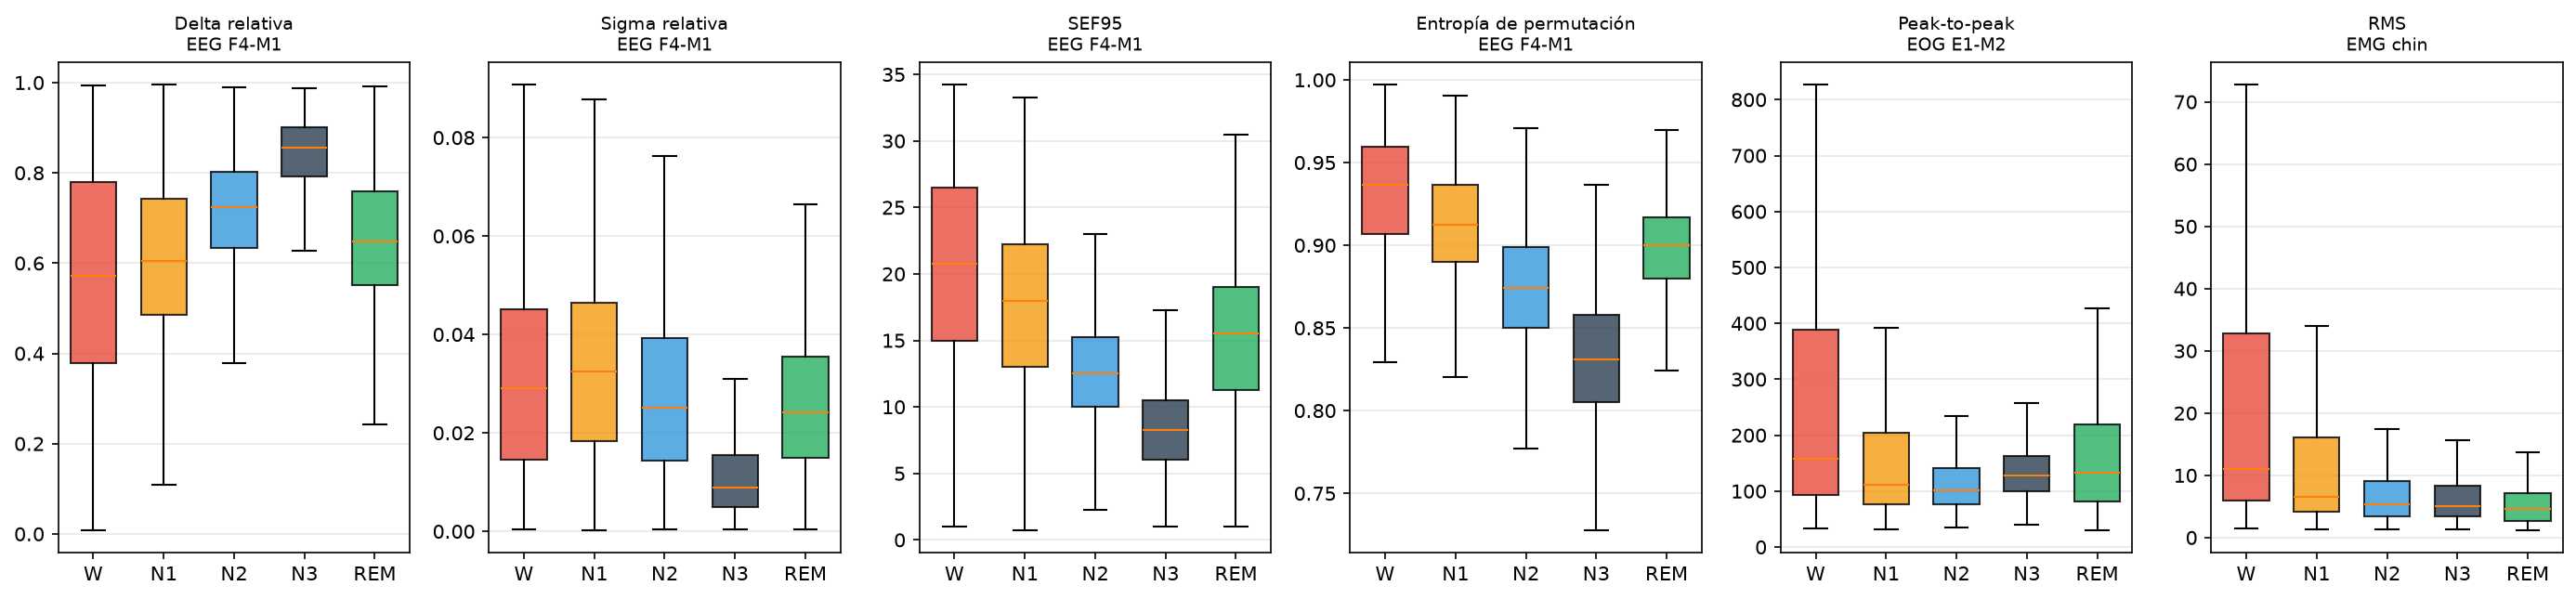

In [16]:
from IPython.display import display, Image

if BOXPLOT_PATH.exists():
    display(
        Image(
            filename=str(BOXPLOT_PATH),
            width=1200,
        )
    )


### 6.1 Perfil espectral promedio del EEG principal


In [17]:
HEATMAP_PATH = FIGURES_DIR / "relative_band_power_heatmap.png"

if main_eeg is None:
    print("No se detectó ningún canal EEG.")
else:
    relative_band_cols = [
        f"{main_eeg}__{band}_rel"
        for band in FREQ_BANDS
        if f"{main_eeg}__{band}_rel" in features_df.columns
    ]

    if not relative_band_cols:
        print("No se encontraron columnas de potencia relativa.")
    else:
        profile = (
            features_df
            .groupby("label", observed=True)[relative_band_cols]
            .mean()
        )

        profile.index = [STAGE_MAP[idx] for idx in profile.index]
        profile.columns = [
            col.replace(f"{main_eeg}__", "").replace("_rel", "")
            for col in profile.columns
        ]

        display(profile.round(4))

        fig, ax = plt.subplots(figsize=(7.5, 4.2))
        image = ax.imshow(profile.to_numpy(dtype=np.float32), aspect="auto")

        ax.set_xticks(range(len(profile.columns)), profile.columns)
        ax.set_yticks(range(len(profile.index)), profile.index)
        ax.set_title(f"Potencia relativa promedio por stage — {main_eeg}")
        fig.colorbar(image, ax=ax, label="Potencia relativa")

        for row_idx, row in enumerate(profile.to_numpy()):
            for col_idx, value in enumerate(row):
                ax.text(
                    col_idx,
                    row_idx,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    fontsize=9,
                )

        fig.tight_layout()
        fig.savefig(HEATMAP_PATH, dpi=150, bbox_inches="tight")
        plt.close(fig)

        print("Heatmap guardado:", HEATMAP_PATH.resolve())


,delta,theta,alpha,sigma,beta
W,0.5777,0.1087,0.1260,0.0328,0.1173
N1,0.6158,0.1334,0.1044,0.0343,0.0869
N2,0.7142,0.1190,0.0852,0.0303,0.0382
N3,0.8391,0.0772,0.0487,0.0128,0.0132
REM,0.6558,0.1517,0.0784,0.0271,0.0652


Heatmap guardado: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\figures\relative_band_power_heatmap.png


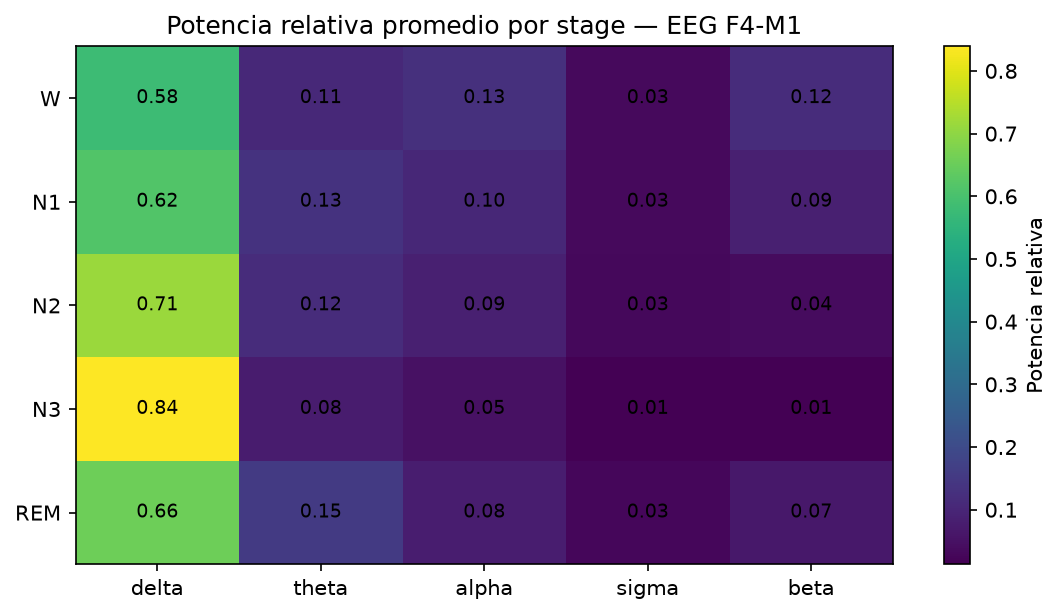

In [18]:
if HEATMAP_PATH.exists():
    display(
        Image(
            filename=str(HEATMAP_PATH),
            width=850,
        )
    )


### 6.2 Diagnóstico de correlación


In [19]:
correlation_matrix = features_df[FEATURE_COLS].corr().abs()
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .rename("abs_corr")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
    .query("abs_corr >= @HIGH_CORR_THRESHOLD")
    .sort_values("abs_corr", ascending=False)
)

print(
    f"Pares con correlación absoluta ≥ "
    f"{HIGH_CORR_THRESHOLD}: {len(high_corr_pairs)}"
)
display(high_corr_pairs.head(20))


Pares con correlación absoluta ≥ 0.95: 40


,feature_a,feature_b,abs_corr
31604,EMG chin__std,EMG chin__rms,1.000000
26368,EOG E2-M2__std,EOG E2-M2__rms,1.000000
188,EEG F4-M1__std,EEG F4-M1__rms,1.000000
5424,EEG C4-M1__std,EEG C4-M1__rms,1.000000
15896,EEG C3-M2__std,EEG C3-M2__rms,1.000000
10660,EEG O2-M1__std,EEG O2-M1__rms,1.000000
21132,EOG E1-M2__std,EOG E1-M2__rms,1.000000
32729,EMG chin__hjorth_activity,EMG chin__total_power_0_5_35,0.990050
2058,EEG F4-M1__total_power_0_5_35,EEG F4-M1__delta_abs,0.985697
12530,EEG O2-M1__total_power_0_5_35,EEG O2-M1__delta_abs,0.985684


### Extra

El ranking univariado siguiente se usa solo como **EDA**. Si más adelante se hace selección de features para entrenar modelos, debe realizarse únicamente con los datos de entrenamiento dentro de cada split por sujeto.


,epochs,percentage
label,,
W,23493,17.34
N1,14846,10.96
N2,49455,36.51
N3,26671,19.69
REM,21006,15.51


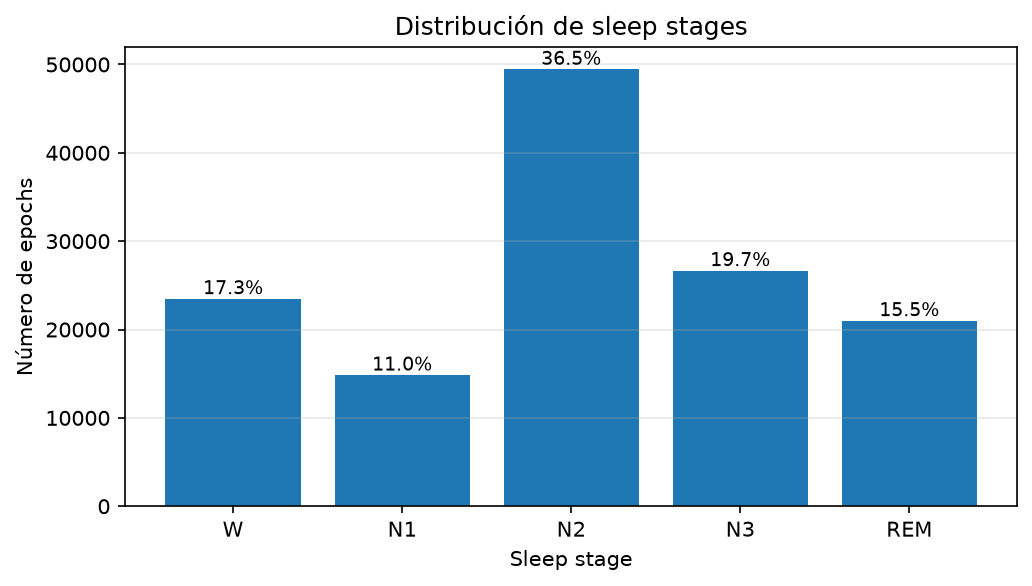

In [20]:
stage_counts = (
    features_df["label"]
    .value_counts()
    .sort_index()
    .rename(index=STAGE_MAP)
)

stage_percentages = 100 * stage_counts / stage_counts.sum()

stage_summary = pd.DataFrame({
    "epochs": stage_counts,
    "percentage": stage_percentages,
})

display(stage_summary.round(2))

CLASS_PLOT_PATH = FIGURES_DIR / "stage_distribution.png"

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    stage_summary.index,
    stage_summary["epochs"],
)

ax.set_title("Distribución de sleep stages")
ax.set_xlabel("Sleep stage")
ax.set_ylabel("Número de epochs")
ax.grid(axis="y", alpha=0.3)

for bar, percentage in zip(bars, stage_summary["percentage"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.tight_layout()
fig.savefig(CLASS_PLOT_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(CLASS_PLOT_PATH), width=750))

In [21]:
def univariate_separation_score(data, feature_cols):
    scores = []

    global_means = data[feature_cols].mean()

    for feature in feature_cols:
        grouped = data.groupby("label")[feature]

        class_counts = grouped.count()
        class_means = grouped.mean()
        class_variances = grouped.var().fillna(0)

        between_variance = (
            class_counts
            * (class_means - global_means[feature]) ** 2
        ).sum()

        within_variance = (
            (class_counts - 1).clip(lower=0)
            * class_variances
        ).sum()

        score = between_variance / (within_variance + EPS)

        scores.append({
            "feature": feature,
            "separation_score": score,
        })

    return (
        pd.DataFrame(scores)
        .sort_values("separation_score", ascending=False)
        .reset_index(drop=True)
    )


separation_df = univariate_separation_score(
    features_df,
    FEATURE_COLS,
)

display(separation_df.head(20))

,feature,separation_score
0,EEG C3-M2__zcr,0.833254
1,EEG C3-M2__perm_entropy,0.792547
2,EEG F4-M1__perm_entropy,0.779482
3,EEG C4-M1__zcr,0.757520
4,EEG C4-M1__perm_entropy,0.756325
5,EEG F4-M1__zcr,0.620919
6,EEG O2-M1__zcr,0.596114
7,EEG C3-M2__beta_rel,0.533649
8,EEG C4-M1__beta_rel,0.532574
9,EEG C4-M1__sef95,0.501788


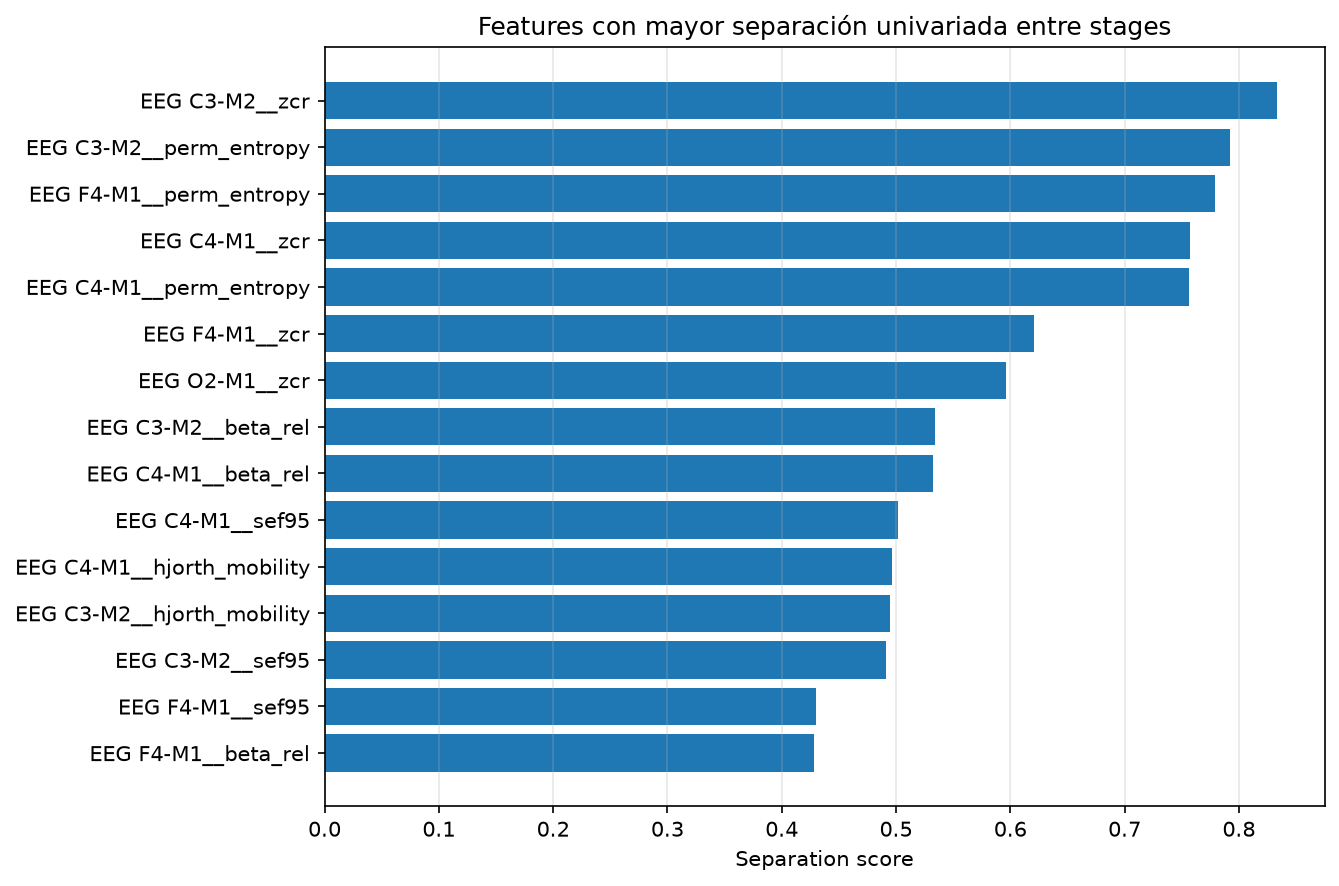

In [22]:
TOP_N = 15

top_features = (
    separation_df
    .head(TOP_N)
    .sort_values("separation_score")
)

SEPARATION_PATH = FIGURES_DIR / "top_univariate_features.png"

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_features["feature"],
    top_features["separation_score"],
)

ax.set_title("Features con mayor separación univariada entre stages")
ax.set_xlabel("Separation score")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(SEPARATION_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(SEPARATION_PATH), width=950))

In [23]:
top_feature_names = separation_df.head(5)["feature"].tolist()

subject_variability = (
    features_df
    .groupby(["subject", "label"], observed=True)[top_feature_names]
    .mean()
    .reset_index()
)

subject_variability.head()

,subject,label,EEG C3-M2__zcr,EEG C3-M2__perm_entropy,EEG F4-M1__perm_entropy,EEG C4-M1__zcr,EEG C4-M1__perm_entropy
0,SN001,0,0.147694,0.921080,0.932686,0.154701,0.921619
1,SN001,1,0.129331,0.897568,0.901836,0.135614,0.897549
2,SN001,2,0.105743,0.851234,0.855984,0.110117,0.848539
3,SN001,3,0.084941,0.832990,0.836578,0.090407,0.829125
4,SN001,4,0.111508,0.899407,0.899800,0.114357,0.897135


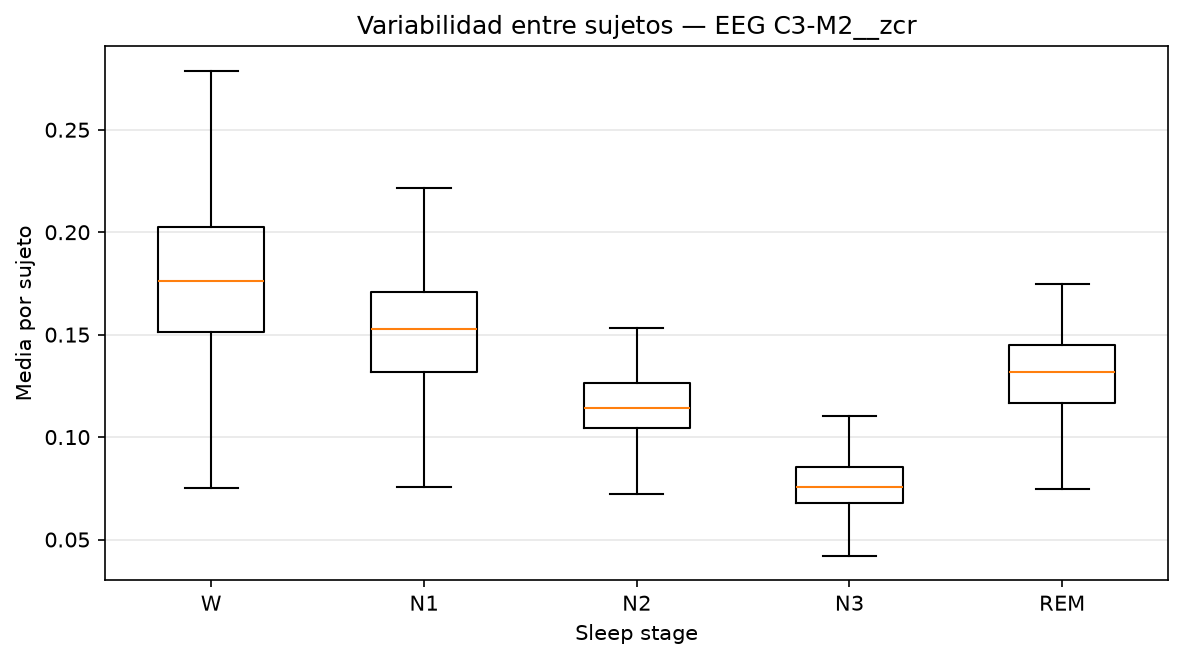

In [24]:
feature_to_plot = top_feature_names[0]

SUBJECT_PLOT_PATH = FIGURES_DIR / "subject_variability.png"

plot_df = (
    subject_variability[
        ["subject", "label", feature_to_plot]
    ]
    .dropna()
)

stage_ids = sorted(plot_df["label"].unique())

fig, ax = plt.subplots(figsize=(8, 4.5))

values_by_stage = [
    plot_df.loc[
        plot_df["label"] == stage_id,
        feature_to_plot,
    ].to_numpy()
    for stage_id in stage_ids
]

ax.boxplot(
    values_by_stage,
    tick_labels=[STAGE_MAP[idx] for idx in stage_ids],
    showfliers=False,
)

ax.set_title(
    f"Variabilidad entre sujetos — {feature_to_plot}"
)
ax.set_xlabel("Sleep stage")
ax.set_ylabel("Media por sujeto")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(SUBJECT_PLOT_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)

display(Image(filename=str(SUBJECT_PLOT_PATH), width=850))

---
## 7. Catálogo y guardado final


In [25]:
def feature_family(feature_name):
    suffix = feature_name.split("__", 1)[-1]

    if suffix.startswith("hjorth_"):
        return "hjorth"
    if "entropy" in suffix:
        return "entropy"
    if suffix in {"mean", "std", "rms", "ptp", "skew", "kurt", "zcr"}:
        return "temporal"
    return "spectral"


feature_catalog = pd.DataFrame({
    "feature": FEATURE_COLS,
    "channel": [name.split("__", 1)[0] for name in FEATURE_COLS],
    "family": [feature_family(name) for name in FEATURE_COLS],
    "variance": [float(feature_variance[name]) for name in FEATURE_COLS],
})

feature_catalog["channel_type"] = (
    feature_catalog["channel"].map(infer_channel_type)
)
feature_catalog["is_constant"] = (
    feature_catalog["variance"] <= 1e-12
)

display(
    pd.crosstab(
        feature_catalog["channel_type"],
        feature_catalog["family"],
    )
)


family,entropy,hjorth,spectral,temporal
channel_type,,,,
EEG,8,12,64,28
EMG,2,3,6,7
EOG,4,6,32,14


In [26]:
features_df.to_parquet(
    FINAL_PARQUET,
    index=False,
    compression="snappy",
)

feature_catalog.to_csv(CATALOG_PATH, index=False)

np.savez_compressed(
    FINAL_NPZ,
    X_features=features_df[FEATURE_COLS].to_numpy(dtype=np.float32),
    y=features_df["label"].to_numpy(dtype=np.int8),
    subjects=features_df["subject"].astype(str).to_numpy(),
    epoch_global=features_df["epoch_global"].to_numpy(dtype=np.int32),
    epoch_in_subject=features_df["epoch_in_subject"].to_numpy(dtype=np.int32),
    source_epoch_index=features_df["source_epoch_index"].to_numpy(dtype=np.int32),
    recording_onset_s=features_df["recording_onset_s"].to_numpy(dtype=np.float64),
    qc_status=features_df["qc_status"].astype(str).to_numpy(),
    qc_reason=features_df["qc_reason"].astype(str).to_numpy(),
    review_mask=features_df["review_mask"].to_numpy(dtype=bool),
    feature_names=np.asarray(FEATURE_COLS),
)

print("Parquet: ", FINAL_PARQUET.resolve())
print("NPZ:     ", FINAL_NPZ.resolve())
print("Catálogo:", CATALOG_PATH.resolve())


Parquet:  C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed\features_full.parquet
NPZ:      C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed\features_full.npz
Catálogo: C:\Users\tolot\Documents\UBA\2026\TP\Datasets\processed\feature_catalog.csv


---
## 8. Checklist final


In [27]:
checks = {
    "Mismos epochs que NB2": len(features_df) == current_n_epochs,
    "Mismos sujetos que NB2": (
        set(features_df["subject"].astype(str).unique())
        == set(current_subject_ids)
    ),
    "Sin NaN ni infinitos": np.isfinite(
        features_df[FEATURE_COLS].to_numpy()
    ).all(),
    "Trazabilidad temporal": all(
        col in features_df.columns
        for col in ["source_epoch_index", "recording_onset_s"]
    ),
    "Metadata QC": all(
        col in features_df.columns
        for col in ["qc_status", "review_mask"]
    ),
    "Parquet guardado": FINAL_PARQUET.exists(),
    "NPZ guardado": FINAL_NPZ.exists(),
    "Catálogo guardado": CATALOG_PATH.exists(),
}

print("=" * 68)
print("CHECKLIST — FEATURE ENGINEERING")
print("=" * 68)

for label, passed in checks.items():
    print(f"{'✅' if passed else '❌'}  {label}")

print("\nResumen:")
print(f"  epochs:              {len(features_df)}")
print(f"  sujetos:             {features_df['subject'].nunique()}")
print(f"  features:            {len(FEATURE_COLS)}")
print(f"  features constantes: {len(constant_features)}")
print(f"  epochs review:       {int(features_df['review_mask'].sum())}")

print("\nPróximo paso:")
print("  Entrenar el baseline con validación agrupada por sujeto.")


CHECKLIST — FEATURE ENGINEERING
✅  Mismos epochs que NB2
✅  Mismos sujetos que NB2
✅  Sin NaN ni infinitos
✅  Trazabilidad temporal
✅  Metadata QC
✅  Parquet guardado
✅  NPZ guardado
✅  Catálogo guardado

Resumen:
  epochs:              135471
  sujetos:             149
  features:            186
  features constantes: 0
  epochs review:       9991

Próximo paso:
  Entrenar el baseline con validación agrupada por sujeto.
